In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns
from scipy.linalg import inv, det
from scipy.stats import norm
#print(norm.cdf(x, mean, std))

%matplotlib inline

In [2]:
def hinton(matrix, xlabel = None, ylabel = None, max_weight=None, ax=None):
    """Draw Hinton diagram for visualizing a weight matrix."""
    ax = ax if ax is not None else plt.gca()
    print(matrix.shape)
    if not max_weight:
        max_weight = 2 ** np.ceil(np.log2(np.abs(matrix).max()))

    ax.patch.set_facecolor('gray')
    ax.set_aspect('equal', 'box')
    ax.xaxis.set_major_locator(plt.NullLocator())
    ax.yaxis.set_major_locator(plt.NullLocator())

    for (x, y), w in np.ndenumerate(matrix):
        color = 'white' if w > 0 else 'black'
        size = np.sqrt(abs(w) / max_weight)
        rect = plt.Rectangle([x - size / 2, y - size / 2], size, size,
                             facecolor=color, edgecolor=color)
        ax.add_patch(rect)

    if xlabel:
        ax.set_xticks(np.arange(matrix.shape[0]))
        ax.set_xticklabels(xlabel)
    if ylabel:
        ax.set_yticks(np.arange(matrix.shape[1]))
        ax.set_yticklabels(ylabel)
    ax.autoscale_view()
    ax.invert_yaxis()
    
def surface(x,y,z,titre):
    fig = plt.figure()
    axes = fig.gca(projection='3d')
    Gx, Gy = np.gradient(z) # gradients with respect to x and y
    G = (Gx**2+Gy**2)**.5  # gradient magnitude
    N = G/G.max()  # normalize 0..1
    axes.plot_surface(
        x, y, z, rstride=1, cstride=1,
        facecolors=cm.jet(N),
        linewidth=0, antialiased=False, shade=False)
    axes.set_title(titre)
    plt.show()

In [ ]:
p = np.array([[0, 0.3], [0.1, 0.6]])

hinton(p)

### Distribution normale multivariée

Influence de la forme de la matrice de covariance

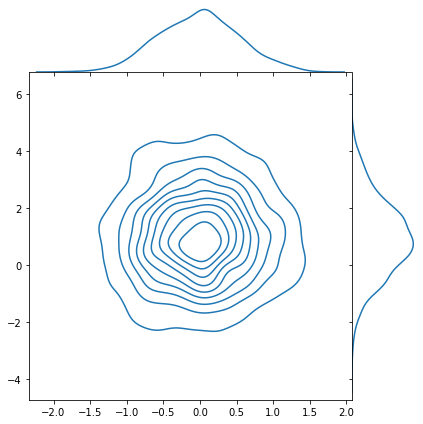

In [5]:
mu = np.array([0.0, 1.0])
#sigma = np.array([[0.8, 0.7],[0.7, 1.3]]) # full
#sigma = np.array([[3.9, -0.5],[-0.5, 1.1]]) # full
sigma = np.array([[0.3, 0.0],[0.0, 1.8]]) # diago

z = np.random.multivariate_normal(mean=mu, cov=sigma, size=2000)
y = np.transpose(z)
# Plot density function.
sns.jointplot(x=y[0], y=y[1], kind="kde", space=0);

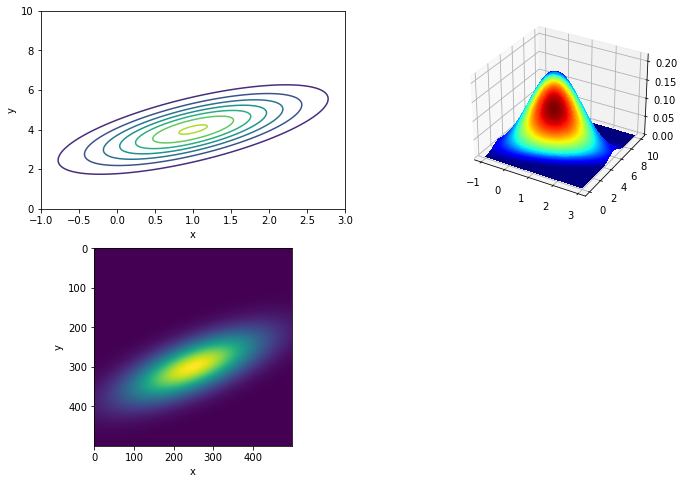

In [6]:
def gaussian(x, y, m, s):
    invS = inv(s)
    exposant = (x - m[0])*(x - m[0])*invS[0,0] + 2*(x-m[0])*(y-m[1])* invS[0,1]+ (y -m[1])*(y-m[1])*invS[1,1]
    denominateur = (2*np.pi) * np.sqrt(det(s))
    return 1/denominateur * np.exp(-exposant/2)


mu = np.array([1.0, 4.0])
sigma = np.array([[0.8, 0.7],[0.7, 1.3]]) # full
#sigma = np.array([[3.9, -0.5],[-0.5, 1.1]]) # full
#sigma = np.array([[0.3, 0.0],[0.0, 1.8]]) # diago
x0 = np.linspace(-1, 3, 500)
y0 = np.linspace(0, 10, 500)
x,y = np.meshgrid(x0,y0)
fxy = gaussian(x,y,mu, sigma)

fig = plt.figure(figsize =(12,8))
ax1 = fig.add_subplot(221)
ax1.contour(x, y, fxy)
plt.xlabel('x')
plt.ylabel('y')

ax2 = fig.add_subplot(222, projection='3d')
Gx, Gy = np.gradient(fxy) # gradients with respect to x and y
G = (Gx**2+Gy**2)**.5  # gradient magnitude
N = G/G.max()  # normalize 0..1
ax2.plot_surface(
    x, y, fxy, rstride=1, cstride=1,
    facecolors=cm.jet(N),
    linewidth=0, antialiased=False, shade=False)

ax3 = fig.add_subplot(223)
ax3.imshow(np.fliplr(np.flip(fxy)))
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### Lois marginales

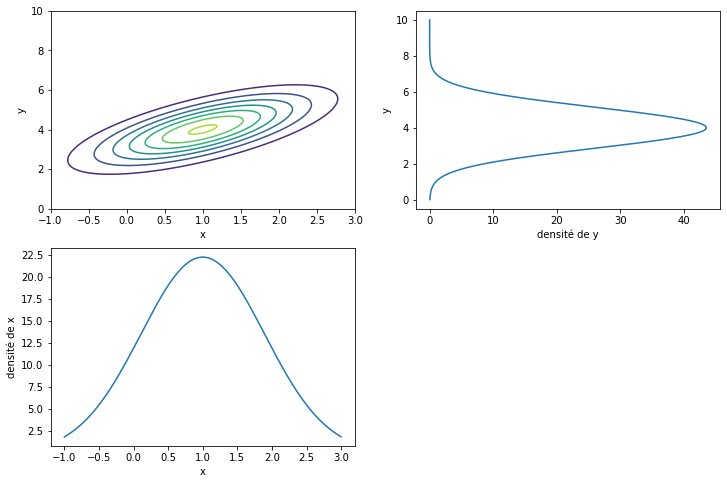

In [7]:
px = np.sum(fxy, axis = 0)
py = np.sum(fxy, axis = 1)

fig = plt.figure(figsize =(12,8))
ax1 = fig.add_subplot(221)
ax1.contour(x, y, fxy)
plt.xlabel('x')
plt.ylabel('y')

ax2 = fig.add_subplot(223)
ax2.plot(x0, px)
ax2.set_xlabel('x')
ax2.set_ylabel('densité de x')

ax3 = fig.add_subplot(222)
ax3.plot(py, y0)
ax3.set_xlabel('densité de y')
ax3.set_ylabel('y')

plt.show()

## Exemple sur de vraies données

On récupère ici les données de nombres manuscrits. Il y en a 1797 encodés sur $8\times8$ pixels avec un niveau de gris.

['setosa' 'versicolor' 'virginica']


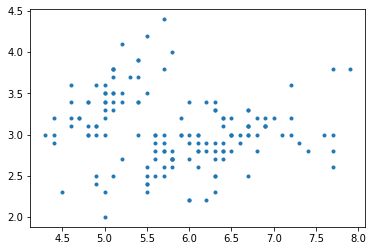

In [10]:
from sklearn.datasets import load_iris

iris = load_iris()
data = iris['data'][:,:2]
labels = iris['target']
iris_names = iris['target_names']
print(iris_names)
plt.plot(data[:,0], data[:,1], '.')
plt.show()

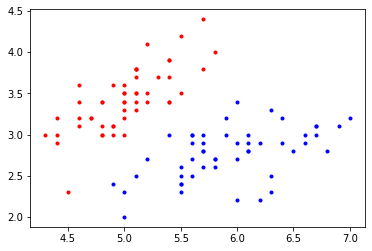

In [11]:
X0 = data[(labels==0),:]
X1 = data[(labels==1),:]
plt.plot(X0[:,0], X0[:,1], 'r.')
plt.plot(X1[:,0], X1[:,1], 'b.')
plt.show()

Modélisons la distribution de nos données par une loi normale multivariée

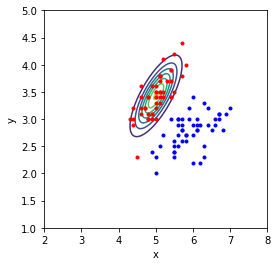

In [12]:
m0 = np.mean(X0, axis=0)
s0 = np.cov(X0.T)
x0 = np.linspace(2, 8, 500)
y0 = np.linspace(1, 5, 500)
x,y = np.meshgrid(x0,y0)
fxy = gaussian(x,y,m0, s0)

fig = plt.figure(figsize =(4,4))
plt.contour(x, y, fxy)
plt.plot(X0[:,0], X0[:,1], 'r.')
plt.plot(X1[:,0], X1[:,1], 'b.')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

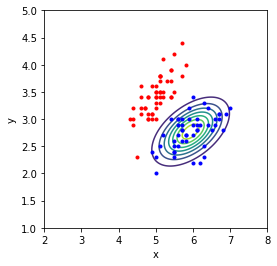

In [13]:
m1 = np.mean(X1, axis=0)
s1 = np.cov(X1.T)
#x0 = np.linspace(-10, 20, 500)
#y0 = np.linspace(-10, 20, 500)
#x,y = np.meshgrid(x0,y0)
gxy = gaussian(x,y,m1, s1)

fig = plt.figure(figsize =(4,4))
plt.contour(x, y, gxy)
plt.plot(X0[:,0], X0[:,1], 'r.')
plt.plot(X1[:,0], X1[:,1], 'b.')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

Est-ce que la matrice de covariance est diagonale ?